<div style="background: linear-gradient(135deg,#0A0E3D 0%,#1A237E 100%);padding:40px 36px 32px 36px;border-radius:12px;color:white;font-family:Arial,sans-serif">
<div style="font-size:13px; letter-spacing:2px; opacity:.75; margin-bottom:8px">UNIVERSIDAD EXTERNADO DE COLOMBIA · CIENCIA DE DATOS · 2026</div>
<h1 style="margin:0 0 6px 0; font-size:28px; font-weight:700; line-height:1.2">Ajuste de hiperparámetros — XGBoost Tweedie</h1>
<h2 style="margin:0 0 20px 0; font-size:17px; font-weight:400; opacity:.9">Búsqueda bayesiana (Optuna) sobre la capa Gold de SPARCS 2021</h2>
<hr style="border:none; border-top:1px solid rgba(255,255,255,.3); margin:0 0 18px 0"/>
<div style="display:flex; gap:40px; font-size:13px; opacity:.85">
<div><b>Autores:</b><br>Daniel Vallejo Vecil<br>Juliana Muñoz González</div>
<div><b>Director:</b><br>Julián F. Sánchez López</div>
<div><b>Capa consumida:</b><br>3_gold</div>
</div></div>

<div style="background:#1A237E;padding:18px;border-radius:8px;color:white;font-family:Arial,sans-serif">
<h2 style="margin:0;">1. Objetivo</h2>
</div>

<div style="background:#F5F9FF;border-left:6px solid #1565C0;padding:18px;border-radius:0 0 8px 8px;font-family:Arial,sans-serif">

Buscar de forma sistemática los hiperparámetros del modelo seleccionado (XGBoost con pérdida de Tweedie, una sola etapa), incluido el <b>parámetro de varianza</b> como variable continua, y verificar si el modelo ajustado supera al de referencia del cuaderno <code>05_Modeling_SPARCS</code> (R² = 0,4646 en prueba).

<b>Protocolo:</b>
<ol>
<li>La búsqueda usa <b>solo la partición de entrenamiento</b>: una submuestra se divide en ajuste y validación interna. El conjunto de prueba no interviene en ninguna decisión.</li>
<li>Las 5 mejores configuraciones se reevalúan con validación cruzada de 3 pliegues, para no elegir una configuración que solo ganó por azar en una partición.</li>
<li>La configuración ganadora se reentrena sobre el entrenamiento completo y se evalúa <b>una sola vez</b> sobre prueba, junto al modelo de referencia.</li>
</ol>

</div>

<div style="background:#1A237E;padding:18px;border-radius:8px;color:white;font-family:Arial,sans-serif">
<h2 style="margin:0;">2. Configuración</h2>
</div>

In [2]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import optuna
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ---------------- Parámetros del experimento ----------------
SEED           = 42
FRAC_BUSQUEDA  = 0.20     # fracción del train usada en la búsqueda (20 %, como en 08_DobleValla)
FRAC_VALID     = 0.20     # validación interna dentro de esa submuestra
N_TRIALS       = 60       # número de configuraciones a probar
TIMEOUT_SEG    = 4 * 3600 # tope de tiempo de la búsqueda (se detiene lo que ocurra primero)
TOP_K_CV       = 5        # configuraciones que pasan a validación cruzada
N_FOLDS_CV     = 3
MAX_ROUNDS     = 5000
EARLY_STOP     = 100
UMBRAL_MEJORA  = 0.005    # ganancia mínima de R² en prueba para adoptar el modelo ajustado

# ---------------- Rutas ----------------
GOLD_PATH    = Path("../data/3_gold")
TABLAS_PATH  = Path("../tablas");  TABLAS_PATH.mkdir(parents=True, exist_ok=True)
FIGURAS_PATH = Path("../figuras"); FIGURAS_PATH.mkdir(parents=True, exist_ok=True)
MODELOS_PATH = Path("../modelos"); MODELOS_PATH.mkdir(parents=True, exist_ok=True)
NOTEBOOK_NUM = "12"

# Hiperparámetros del modelo de referencia (05_Modeling_SPARCS)
PARAMS_REFERENCIA = dict(
    objective="reg:tweedie", tweedie_variance_power=1.5,
    n_estimators=500, max_depth=8, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
)

def guardar_tabla(tabla, nombre):
    archivo = TABLAS_PATH / f"{NOTEBOOK_NUM}_{nombre}.csv"
    tabla.to_csv(archivo, encoding="utf-8-sig")
    print(f"Tabla guardada: {archivo.resolve()}")

def metricas(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "R2": r2_score(y_true, y_pred),
            "Pred_media": float(np.mean(y_pred))}

print("xgboost", xgb.__version__, "| optuna", optuna.__version__)

xgboost 3.4.1 | optuna 5.0.0


c:\Users\danie\miniconda3\envs\tesis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<div style="background:#1A237E;padding:18px;border-radius:8px;color:white;font-family:Arial,sans-serif">
<h2 style="margin:0;">3. Carga de la capa Gold</h2>
</div>

<div style="background:#F5F9FF;border-left:6px solid #1565C0;padding:18px;border-radius:0 0 8px 8px;font-family:Arial,sans-serif">

Se cargan los cuatro objetos Parquet de la capa Gold. Si los nombres de archivo difieren, ajusta el diccionario <code>ARCHIVOS</code>; la celda intenta detectarlos automáticamente.

</div>

In [3]:
def buscar(patron):
    encontrados = sorted(GOLD_PATH.glob(patron))
    if not encontrados:
        raise FileNotFoundError(f"No se encontró {patron} en {GOLD_PATH.resolve()}")
    return encontrados[0]

ARCHIVOS = {
    "X_train": buscar("*X_train*.parquet"),
    "X_test":  buscar("*X_test*.parquet"),
    "y_train": buscar("*y_train*.parquet"),
    "y_test":  buscar("*y_test*.parquet"),
}
for k, v in ARCHIVOS.items():
    print(f"{k:8s} -> {v.name}")

X_train = pd.read_parquet(ARCHIVOS["X_train"])
X_test  = pd.read_parquet(ARCHIVOS["X_test"])
y_train = pd.read_parquet(ARCHIVOS["y_train"]).squeeze("columns").astype("float32")
y_test  = pd.read_parquet(ARCHIVOS["y_test"]).squeeze("columns").astype("float32")

assert list(X_train.columns) == list(X_test.columns), "Las columnas de train y test no coinciden"
print(f"\nTrain: {X_train.shape} | Test: {X_test.shape}")
print(f"Estancia media train: {y_train.mean():.2f} | test: {y_test.mean():.2f}")

X_train  -> X_train_sparcs.parquet
X_test   -> X_test_sparcs.parquet
y_train  -> y_train_sparcs.parquet
y_test   -> y_test_sparcs.parquet

Train: (1672271, 189) | Test: (418068, 189)
Estancia media train: 5.74 | test: 5.72


<div style="background:#1A237E;padding:18px;border-radius:8px;color:white;font-family:Arial,sans-serif">
<h2 style="margin:0;">4. Submuestra de búsqueda y validación interna</h2>
</div>

In [4]:
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=FRAC_BUSQUEDA, random_state=SEED)
X_fit, X_val, y_fit, y_val = train_test_split(X_sub, y_sub, test_size=FRAC_VALID, random_state=SEED)

d_fit = xgb.DMatrix(X_fit, label=y_fit)
d_val = xgb.DMatrix(X_val, label=y_val)

print(f"Ajuste: {len(y_fit):,} | Validación interna: {len(y_val):,}")

Ajuste: 267,563 | Validación interna: 66,891


<div style="background:#1A237E;padding:18px;border-radius:8px;color:white;font-family:Arial,sans-serif">
<h2 style="margin:0;">5. Línea base en la validación interna</h2>
</div>

<div style="background:#F5F9FF;border-left:6px solid #1565C0;padding:18px;border-radius:0 0 8px 8px;font-family:Arial,sans-serif">

Se evalúa la configuración de referencia sobre la misma partición interna, para que la comparación con los ensayos de Optuna sea directa. Se registra también como primer ensayo del estudio.

</div>

In [5]:
params_base = {
    "objective": "reg:tweedie", "tweedie_variance_power": 1.5,
    "max_depth": 8, "learning_rate": 0.05, "subsample": 0.8, "colsample_bytree": 0.8,
    "tree_method": "hist", "seed": SEED, "eval_metric": "rmse",
}
t0 = time.time()
bst_base = xgb.train(params_base, d_fit, num_boost_round=500)
r2_base_val = r2_score(y_val, bst_base.predict(d_val))
print(f"R² validación interna (referencia, 500 árboles): {r2_base_val:.4f}  [{time.time()-t0:.0f} s]")

R² validación interna (referencia, 500 árboles): 0.4470  [15 s]


<div style="background:#1A237E;padding:18px;border-radius:8px;color:white;font-family:Arial,sans-serif">
<h2 style="margin:0;">6. Búsqueda bayesiana con Optuna</h2>
</div>

<div style="background:#F1F8F1;border-left:6px solid #2E7D32;padding:18px;border-radius:0 0 8px 8px;font-family:Arial,sans-serif">

<b>Espacio de búsqueda.</b> El parámetro de varianza se explora como continuo entre 1,05 y 1,95 (en <code>05</code> solo se probaron 1,2, 1,5 y 1,8). El número de árboles no se fija: cada ensayo usa <i>early stopping</i> sobre la validación interna, y el número óptimo queda registrado.

<b>Criterio.</b> Se maximiza el R² en validación, coherente con el criterio de selección de la tesis. MAE y RMSE se registran para cada ensayo.

<b>Persistencia.</b> El estudio se guarda en SQLite: si el kernel se interrumpe, al volver a ejecutar la celda continúa donde quedó.

</div>

In [6]:
def objetivo(trial):
    params = {
        "objective": "reg:tweedie",
        "tweedie_variance_power": trial.suggest_float("tweedie_variance_power", 1.05, 1.95),
        "max_depth":        trial.suggest_int("max_depth", 4, 14),
        "learning_rate":    trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 200, log=True),
        "subsample":        trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
        "gamma":            trial.suggest_float("gamma", 1e-8, 5.0, log=True),
        "lambda":           trial.suggest_float("lambda", 1e-3, 50.0, log=True),
        "alpha":            trial.suggest_float("alpha", 1e-3, 10.0, log=True),
        "tree_method": "hist", "seed": SEED, "eval_metric": "rmse",
    }
    bst = xgb.train(params, d_fit, num_boost_round=MAX_ROUNDS,
                    evals=[(d_val, "val")], early_stopping_rounds=EARLY_STOP,
                    verbose_eval=False)
    n_arboles = bst.best_iteration + 1
    pred = bst.predict(d_val, iteration_range=(0, n_arboles))
    m = metricas(y_val, pred)
    trial.set_user_attr("n_estimators", n_arboles)
    trial.set_user_attr("MAE", m["MAE"])
    trial.set_user_attr("RMSE", m["RMSE"])
    return m["R2"]

estudio = optuna.create_study(
    study_name="xgb_tweedie_sparcs",
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=10),
    storage=f"sqlite:///{(MODELOS_PATH / 'optuna_xgb_tweedie.db').as_posix()}",
    load_if_exists=True,
)

# Encolar la configuración de referencia como punto de partida
if len(estudio.trials) == 0:
    estudio.enqueue_trial({"tweedie_variance_power": 1.5, "max_depth": 8, "learning_rate": 0.05,
                           "min_child_weight": 1, "subsample": 0.8, "colsample_bytree": 0.8,
                           "gamma": 1e-8, "lambda": 1.0, "alpha": 1e-3})

faltan = max(0, N_TRIALS - len([t for t in estudio.trials if t.state.name == "COMPLETE"]))
t0 = time.time()
estudio.optimize(objetivo, n_trials=faltan, timeout=TIMEOUT_SEG, show_progress_bar=True)
print(f"\nEnsayos completados: {len(estudio.trials)} | tiempo: {(time.time()-t0)/60:.1f} min")
print(f"Mejor R² validación: {estudio.best_value:.4f} (referencia: {r2_base_val:.4f})")
print("Mejores parámetros:", estudio.best_params)
print("Árboles:", estudio.best_trial.user_attrs["n_estimators"])

Best trial: 26. Best value: 0.457833: 100%|██████████| 60/60 [1:02:24<00:00, 62.40s/it, 3744.21/14400 seconds]


Ensayos completados: 60 | tiempo: 62.4 min
Mejor R² validación: 0.4578 (referencia: 0.4470)
Mejores parámetros: {'tweedie_variance_power': 1.2802241283075964, 'max_depth': 8, 'learning_rate': 0.01448775131198362, 'min_child_weight': 106.11243351619297, 'subsample': 0.8564839902131433, 'colsample_bytree': 0.6157930885099248, 'gamma': 0.4557312693576054, 'lambda': 46.06602080142691, 'alpha': 2.4988211228188426}
Árboles: 2570


<div style="background:#1A237E;padding:18px;border-radius:8px;color:white;font-family:Arial,sans-serif">
<h2 style="margin:0;">7. Resultados de la búsqueda</h2>
</div>

In [7]:
ensayos = estudio.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "state"))
ensayos = ensayos[ensayos["state"] == "COMPLETE"].rename(columns={"value": "R2_val"})
ensayos.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in ensayos.columns]
ensayos = ensayos.sort_values("R2_val", ascending=False).reset_index(drop=True)
display(ensayos.head(10).round(4))
guardar_tabla(ensayos, "EnsayosOptuna")

,number,R2_val,alpha,colsample_bytree,gamma,lambda,learning_rate,max_depth,min_child_weight,subsample,tweedie_variance_power,MAE,RMSE,n_estimators,state
0,26,0.4578,2.4988,0.6158,0.4557,46.0660,0.0145,8,106.1124,0.8565,1.2802,2.9324,6.1352,2570,COMPLETE
1,41,0.4572,4.6679,0.5439,0.0230,1.5436,0.0140,8,123.6683,0.6980,1.0578,2.9532,6.1389,1884,COMPLETE
2,58,0.4566,5.0217,0.5657,1.2380,16.1588,0.0120,8,91.5214,0.8416,1.1547,2.9421,6.1420,2433,COMPLETE
3,37,0.4564,7.1298,0.6290,0.0661,36.0540,0.0158,8,60.6155,0.7888,1.2512,2.9387,6.1434,1745,COMPLETE
4,31,0.4563,5.6052,0.5677,0.0146,14.3135,0.0110,9,62.2915,0.7023,1.0625,2.9440,6.1436,2100,COMPLETE
5,57,0.4563,6.7278,0.6108,0.0262,34.4831,0.0155,8,116.5697,0.8036,1.1530,2.9456,6.1440,1987,COMPLETE
6,42,0.4563,5.8042,0.4834,0.0862,6.8115,0.0122,8,84.2382,0.7103,1.2694,2.9383,6.1441,2531,COMPLETE
7,44,0.4562,2.0008,0.5489,0.0359,3.4377,0.0173,7,121.4668,0.7015,1.2242,2.9493,6.1445,2088,COMPLETE
8,20,0.4560,6.8451,0.4700,0.4681,31.3443,0.0125,8,114.3261,0.7548,1.1969,2.9419,6.1453,2805,COMPLETE
9,52,0.4560,3.3022,0.4941,0.0130,3.4493,0.0133,9,69.7732,0.6949,1.2148,2.9352,6.1454,1820,COMPLETE


Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\12_EnsayosOptuna.csv


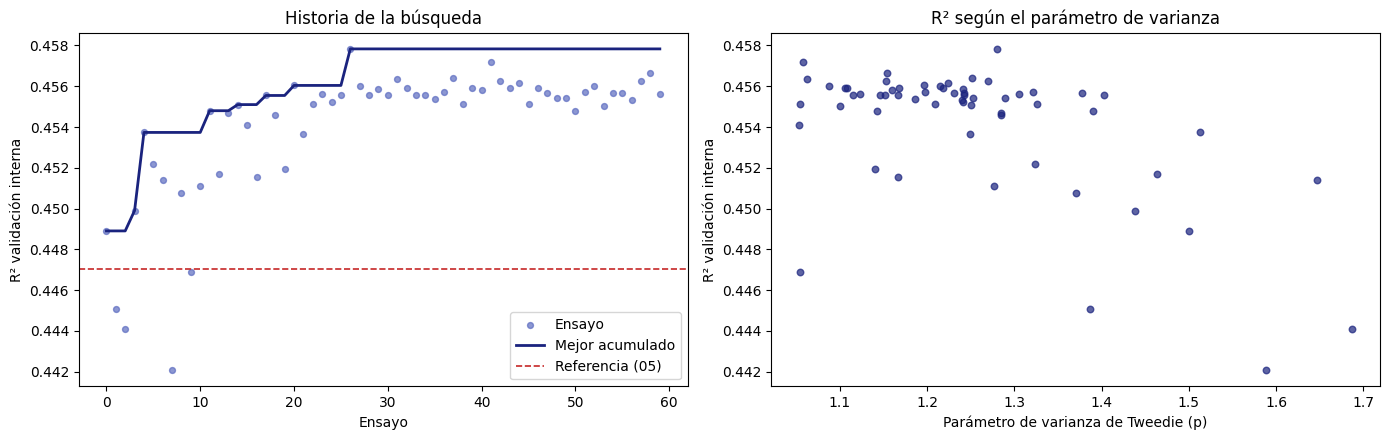

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Historia de la optimización
orden = ensayos.sort_values("number")
axes[0].scatter(orden["number"], orden["R2_val"], s=18, color="#5C6BC0", alpha=.7, label="Ensayo")
axes[0].plot(orden["number"], orden["R2_val"].cummax(), color="#1A237E", lw=2, label="Mejor acumulado")
axes[0].axhline(r2_base_val, color="#C62828", ls="--", lw=1.2, label="Referencia (05)")
axes[0].set_xlabel("Ensayo"); axes[0].set_ylabel("R² validación interna")
axes[0].set_title("Historia de la búsqueda"); axes[0].legend()

# Efecto del parámetro de varianza
axes[1].scatter(ensayos["tweedie_variance_power"], ensayos["R2_val"], s=22, color="#1A237E", alpha=.7)
axes[1].set_xlabel("Parámetro de varianza de Tweedie (p)"); axes[1].set_ylabel("R² validación interna")
axes[1].set_title("R² según el parámetro de varianza")

plt.tight_layout()
plt.savefig(FIGURAS_PATH / f"{NOTEBOOK_NUM}_busqueda_optuna.pdf", bbox_inches="tight")
plt.show()

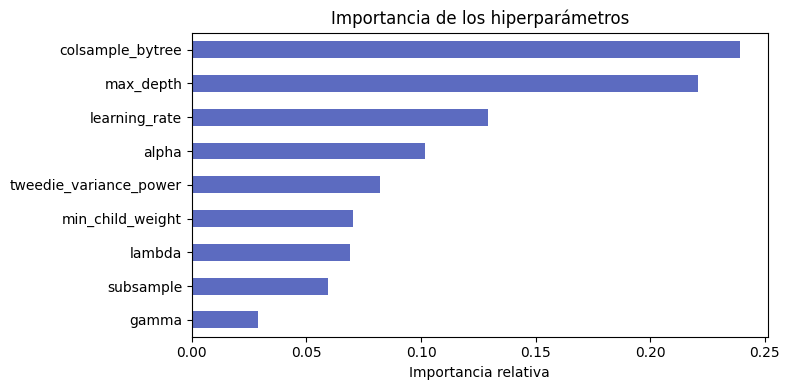

Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\12_ImportanciaHiperparametros.csv


In [9]:
# Importancia relativa de cada hiperparámetro en el R² (fANOVA)
importancias = pd.Series(optuna.importance.get_param_importances(estudio)).sort_values()
ax = importancias.plot.barh(figsize=(8, 4), color="#5C6BC0")
ax.set_title("Importancia de los hiperparámetros"); ax.set_xlabel("Importancia relativa")
plt.tight_layout()
plt.savefig(FIGURAS_PATH / f"{NOTEBOOK_NUM}_importancia_hiperparametros.pdf", bbox_inches="tight")
plt.show()
guardar_tabla(importancias.sort_values(ascending=False).to_frame("importancia"), "ImportanciaHiperparametros")

<div style="background:#1A237E;padding:18px;border-radius:8px;color:white;font-family:Arial,sans-serif">
<h2 style="margin:0;">8. Confirmación con validación cruzada</h2>
</div>

<div style="background:#F5F9FF;border-left:6px solid #1565C0;padding:18px;border-radius:0 0 8px 8px;font-family:Arial,sans-serif">

Las diferencias entre las mejores configuraciones suelen ser de milésimas y pueden deberse a la partición interna. Las <b>top 5</b> y la referencia se reevalúan con validación cruzada de 3 pliegues sobre la submuestra de búsqueda; se elige la de mayor R² medio.

</div>

In [10]:
def cv_config(params, n_arboles, X, y):
    kf = KFold(n_splits=N_FOLDS_CV, shuffle=True, random_state=SEED)
    r2s = []
    for tr, va in kf.split(X):
        bst = xgb.train(params, xgb.DMatrix(X.iloc[tr], label=y.iloc[tr]), num_boost_round=n_arboles)
        r2s.append(r2_score(y.iloc[va], bst.predict(xgb.DMatrix(X.iloc[va]))))
    return np.mean(r2s), np.std(r2s)

candidatas = [("Referencia (05)", {k: v for k, v in params_base.items()}, 500)]
for i, fila in ensayos.head(TOP_K_CV).iterrows():
    p = estudio.trials[int(fila["number"])].params
    params = {"objective": "reg:tweedie", "tree_method": "hist", "seed": SEED, **p}
    candidatas.append((f"Ensayo {int(fila['number'])}", params, int(fila["n_estimators"])))

filas = []
for nombre, params, n_arb in candidatas:
    t0 = time.time()
    media, desv = cv_config(params, n_arb, X_sub, y_sub)
    filas.append({"configuracion": nombre, "R2_cv_media": media, "R2_cv_desv": desv,
                  "n_estimators": n_arb, "p": params["tweedie_variance_power"]})
    print(f"{nombre:18s} R² CV = {media:.4f} ± {desv:.4f}  [{time.time()-t0:.0f} s]")

tabla_cv = pd.DataFrame(filas).sort_values("R2_cv_media", ascending=False).reset_index(drop=True)
display(tabla_cv.round(4))
guardar_tabla(tabla_cv, "ValidacionCruzadaTop")

Referencia (05)    R² CV = 0.4412 ± 0.0036  [36 s]
Ensayo 26          R² CV = 0.4464 ± 0.0045  [159 s]
Ensayo 41          R² CV = 0.4454 ± 0.0037  [179 s]
Ensayo 58          R² CV = 0.4464 ± 0.0040  [185 s]
Ensayo 37          R² CV = 0.4460 ± 0.0040  [127 s]
Ensayo 31          R² CV = 0.4440 ± 0.0035  [174 s]


,configuracion,R2_cv_media,R2_cv_desv,n_estimators,p
0,Ensayo 26,0.4464,0.0045,2570,1.2802
1,Ensayo 58,0.4464,0.0040,2433,1.1547
2,Ensayo 37,0.4460,0.0040,1745,1.2512
3,Ensayo 41,0.4454,0.0037,1884,1.0578
4,Ensayo 31,0.4440,0.0035,2100,1.0625
5,Referencia (05),0.4412,0.0036,500,1.5000


Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\12_ValidacionCruzadaTop.csv


In [11]:
ganadora = tabla_cv[tabla_cv["configuracion"] != "Referencia (05)"].iloc[0]
params_ganadores = next(p for n, p, _ in candidatas if n == ganadora["configuracion"])
n_arboles_sub = int(ganadora["n_estimators"])
print("Configuración ganadora:", ganadora["configuracion"])
print(json.dumps(params_ganadores, indent=2))

Configuración ganadora: Ensayo 26
{
  "objective": "reg:tweedie",
  "tree_method": "hist",
  "seed": 42,
  "tweedie_variance_power": 1.2802241283075964,
  "max_depth": 8,
  "learning_rate": 0.01448775131198362,
  "min_child_weight": 106.11243351619297,
  "subsample": 0.8564839902131433,
  "colsample_bytree": 0.6157930885099248,
  "gamma": 0.4557312693576054,
  "lambda": 46.06602080142691,
  "alpha": 2.4988211228188426
}


<div style="background:#1A237E;padding:18px;border-radius:8px;color:white;font-family:Arial,sans-serif">
<h2 style="margin:0;">9. Reentrenamiento sobre el entrenamiento completo</h2>
</div>

<div style="background:#F5F9FF;border-left:6px solid #1565C0;padding:18px;border-radius:0 0 8px 8px;font-family:Arial,sans-serif">

El número de árboles hallado en la submuestra no es directamente trasladable a un conjunto cinco veces mayor. Se reserva un 10 % del entrenamiento completo para <i>early stopping</i>, se fija así el número de árboles y luego se reentrena sobre el 100 % del entrenamiento con ese número. El conjunto de prueba sigue sin intervenir.

</div>

In [12]:
X_tr90, X_es, y_tr90, y_es = train_test_split(X_train, y_train, test_size=0.10, random_state=SEED)

params_final = {**params_ganadores, "eval_metric": "rmse"}
t0 = time.time()
bst_es = xgb.train(params_final, xgb.DMatrix(X_tr90, label=y_tr90), num_boost_round=MAX_ROUNDS,
                   evals=[(xgb.DMatrix(X_es, label=y_es), "es")],
                   early_stopping_rounds=EARLY_STOP, verbose_eval=500)
n_arboles_final = bst_es.best_iteration + 1
print(f"Árboles óptimos en el train completo: {n_arboles_final} [{(time.time()-t0)/60:.1f} min]")

# Modelo final con API scikit-learn (compatible con el cuaderno de SHAP)
sk_params = {k: v for k, v in params_ganadores.items() if k not in ("eval_metric", "seed", "lambda", "alpha")}
modelo_ajustado = xgb.XGBRegressor(
    **sk_params,
    reg_lambda=params_ganadores.get("lambda", 1.0),
    reg_alpha=params_ganadores.get("alpha", 0.0),
    n_estimators=n_arboles_final, random_state=SEED, n_jobs=-1,
)
t0 = time.time()
modelo_ajustado.fit(X_train, y_train)
print(f"Modelo ajustado entrenado sobre {len(y_train):,} registros [{(time.time()-t0)/60:.1f} min]")

[0]	es-rmse:8.36185
[500]	es-rmse:6.24558
[1000]	es-rmse:6.20527
[1500]	es-rmse:6.17790
[2000]	es-rmse:6.16072
[2500]	es-rmse:6.14769
[3000]	es-rmse:6.13854
[3500]	es-rmse:6.13118
[4000]	es-rmse:6.12630
[4500]	es-rmse:6.12303
[4999]	es-rmse:6.12129
Árboles óptimos en el train completo: 4970 [14.1 min]
Modelo ajustado entrenado sobre 1,672,271 registros [13.8 min]


In [13]:
# Modelo de referencia reentrenado con idénticas condiciones (misma semilla y datos)
modelo_referencia = xgb.XGBRegressor(**PARAMS_REFERENCIA, tree_method="hist",
                                     random_state=SEED, n_jobs=-1)
t0 = time.time()
modelo_referencia.fit(X_train, y_train)
print(f"Modelo de referencia entrenado [{(time.time()-t0)/60:.1f} min]")

Modelo de referencia entrenado [1.6 min]


<div style="background:#1A237E;padding:18px;border-radius:8px;color:white;font-family:Arial,sans-serif">
<h2 style="margin:0;">10. Evaluación final sobre el conjunto de prueba</h2>
</div>

<div style="background:#FFF5F5;border-left:6px solid #C62828;padding:18px;border-radius:0 0 8px 8px;font-family:Arial,sans-serif">

Esta es la <b>única</b> vez que se usa el conjunto de prueba. Se reporta el desempeño global, por subpoblación (neonatal / no neonatal, para la comparación con Jain et al., 2024) y por tramo de estancia.

</div>

In [14]:
pred_ref = modelo_referencia.predict(X_test)
pred_aju = modelo_ajustado.predict(X_test)

# Indicador neonatal: columna one-hot de Type of Admission = Newborn
cols_newborn = [c for c in X_test.columns if "newborn" in c.lower() and "admission" in c.lower()]
print("Columna neonatal detectada:", cols_newborn)
es_neonato = (X_test[cols_newborn[0]] == 1).to_numpy() if cols_newborn else None

poblaciones = {"Población completa": np.ones(len(y_test), dtype=bool)}
if es_neonato is not None:
    poblaciones["No neonatal"] = ~es_neonato
    poblaciones["Neonatal"] = es_neonato
else:
    print("AVISO: no se encontró la columna de Newborn; ajusta cols_newborn manualmente.")

filas = []
for pob, m in poblaciones.items():
    for modelo, pred in [("Referencia (05)", pred_ref), ("Ajustado (Optuna)", pred_aju)]:
        filas.append({"Población": pob, "Modelo": modelo, "n": int(m.sum()),
                      **metricas(y_test.values[m], pred[m])})
tabla_prueba = pd.DataFrame(filas).set_index(["Población", "Modelo"])
display(tabla_prueba.round(4))
guardar_tabla(tabla_prueba, "DesempenoPrueba")

Columna neonatal detectada: ['Type of Admission_Newborn']


n     MAE    RMSE      R2  \
Población          Modelo                                              
Población completa Referencia (05)    418068  2.8931  6.0708  0.4653   
                   Ajustado (Optuna)  418068  2.8636  6.0149  0.4751   
No neonatal        Referencia (05)    379243  3.0633  6.2336  0.4329   
                   Ajustado (Optuna)  379243  3.0324  6.1807  0.4424   
Neonatal           Referencia (05)     38825  1.2306  4.1572  0.7427   
                   Ajustado (Optuna)   38825  1.2149  4.0528  0.7554   

                                      Pred_media  
Población          Modelo                         
Población completa Referencia (05)        5.6510  
                   Ajustado (Optuna)      5.6696  
No neonatal        Referencia (05)        5.8793  
                   Ajustado (Optuna)      5.8986  
Neonatal           Referencia (05)        3.4204  
                   Ajustado (Optuna)      3.4328

Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\12_DesempenoPrueba.csv


In [15]:
tramos = pd.cut(y_test, bins=[0, 2, 6, 13, 29, 119, 121],
                labels=["1–2", "3–6", "7–13", "14–29", "30–119", "120+"])
por_tramo = pd.DataFrame({
    "n": y_test.groupby(tramos, observed=True).size(),
    "MAE referencia": pd.Series(np.abs(y_test - pred_ref)).groupby(tramos, observed=True).mean(),
    "MAE ajustado":   pd.Series(np.abs(y_test - pred_aju)).groupby(tramos, observed=True).mean(),
})
por_tramo["Diferencia"] = por_tramo["MAE ajustado"] - por_tramo["MAE referencia"]
display(por_tramo.round(3))
guardar_tabla(por_tramo, "MAEPorTramo")

,n,MAE referencia,MAE ajustado,Diferencia
Length of Stay,,,,
1–2,165259,1.596000,1.557000,-0.038
3–6,152033,1.853000,1.844000,-0.009
7–13,64491,3.431000,3.452000,0.021
14–29,28338,7.892000,7.814000,-0.078
30–119,7658,25.613001,25.201000,-0.412
120+,289,79.592003,77.494003,-2.098


Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\12_MAEPorTramo.csv


<div style="background:#1A237E;padding:18px;border-radius:8px;color:white;font-family:Arial,sans-serif">
<h2 style="margin:0;">11. Decisión y persistencia</h2>
</div>

In [16]:
r2_ref = tabla_prueba.loc[("Población completa", "Referencia (05)"), "R2"]
r2_aju = tabla_prueba.loc[("Población completa", "Ajustado (Optuna)"), "R2"]
ganancia = r2_aju - r2_ref

print(f"R² prueba — referencia: {r2_ref:.4f} | ajustado: {r2_aju:.4f} | ganancia: {ganancia:+.4f}")
if ganancia >= UMBRAL_MEJORA:
    print("→ La mejora supera el umbral: adoptar el modelo ajustado y actualizar Tabla 4.1, SHAP y conclusiones.")
else:
    print("→ Mejora marginal: conservar el modelo de referencia y reportar el ajuste como análisis de sensibilidad.")

if es_neonato is not None:
    r2_nn = tabla_prueba.loc[("No neonatal", "Ajustado (Optuna)"), "R2"]
    r2_nn_ref = tabla_prueba.loc[("No neonatal", "Referencia (05)"), "R2"]
    print(f"\nR² no neonatal — referencia: {r2_nn_ref:.4f} | ajustado: {r2_nn:.4f} | Jain et al. (2024): ≈ 0,43")

R² prueba — referencia: 0.4653 | ajustado: 0.4751 | ganancia: +0.0098
→ La mejora supera el umbral: adoptar el modelo ajustado y actualizar Tabla 4.1, SHAP y conclusiones.

R² no neonatal — referencia: 0.4329 | ajustado: 0.4424 | Jain et al. (2024): ≈ 0,43


In [17]:
modelo_ajustado.save_model(MODELOS_PATH / f"{NOTEBOOK_NUM}_xgb_tweedie_optuna.json")

resumen = {
    "parametros": {k: (float(v) if isinstance(v, (np.floating, float)) else v)
                   for k, v in params_ganadores.items()},
    "n_estimators_final": int(n_arboles_final),
    "r2_validacion_interna": float(estudio.best_value),
    "r2_cv_media": float(ganadora["R2_cv_media"]),
    "r2_prueba": float(r2_aju),
    "r2_prueba_referencia": float(r2_ref),
    "n_trials": len(estudio.trials),
    "semilla": SEED,
}
with open(MODELOS_PATH / f"{NOTEBOOK_NUM}_mejores_hiperparametros.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False)
print(json.dumps(resumen, indent=2, ensure_ascii=False))

{
  "parametros": {
    "objective": "reg:tweedie",
    "tree_method": "hist",
    "seed": 42,
    "tweedie_variance_power": 1.2802241283075964,
    "max_depth": 8,
    "learning_rate": 0.01448775131198362,
    "min_child_weight": 106.11243351619297,
    "subsample": 0.8564839902131433,
    "colsample_bytree": 0.6157930885099248,
    "gamma": 0.4557312693576054,
    "lambda": 46.06602080142691,
    "alpha": 2.4988211228188426
  },
  "n_estimators_final": 4970,
  "r2_validacion_interna": 0.45783329010009766,
  "r2_cv_media": 0.44642966985702515,
  "r2_prueba": 0.4750823974609375,
  "r2_prueba_referencia": 0.46528714895248413,
  "n_trials": 60,
  "semilla": 42
}
